# B2: Decision features versus label-free text embeddings

Frozen text embeddings (E5-small-v2, E5-large-v2, Qwen3-Embedding-0.6B; PCA fitted on outer-training rows only: 32 components per text column or 64 joint) and each decision model's both-view features combined with E5-small per-column PCA32, compared with the decision features alone. The question: are decision features a better or more compact label-free text representation than generic embeddings, and do they add to them?

Seven predictors use prespecified settings on the same five outer folds across 18 datasets (3 binary, 6 multiclass, 9 regression). They are linear/logistic regression, CatBoost, LightGBM, TabPFN-3.5, TabICL v2, LimiX-2 and Kumo. Each structured baseline includes the non-text columns and one text-availability flag per text column. Fixed headline metrics: binary ROC-AUC, multiclass macro one-vs-rest ROC-AUC, regression R². Datasets are the unit: each contributes its five-fold mean paired gain; raw gains stay within a task family (ΔAUC and ΔR², N = 9 each, separate panels) and only the headroom share (gain / (1 − baseline)) and the MulTaBench-style normalised score (per dataset and fold, min-max over the compared configurations; negative R² clipped at 0) pool all 18 datasets. Means sit next to medians; intervals resample datasets (2,000 draws). Decision medians are taken over all members of the recorded decision-model cohort; nothing selects a winner.

Reads `output_JEVPFN/B/B2/results/group_b/b2_frozen_embeddings.<cohort>-<roster digest>.zip` (`B_export.slurm B2`; the label-trained alternatives are in B3) and, for section 5, the prepared PCA stores under `output_JEVPFN/B/B2/results/pca/`, which exist locally.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import pandas as pd
from src.utils.notebook_display import display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.evaluation import benchmark_export, group_b, group_b_views as views, learner_scores, study_export
from src.visualize import critical_difference, figures, style
from src.visualize import group_b as gbfig
from src.visualize import representation_views
style.apply()
NOTEBOOK = "B/B2"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. What is complete: export, provenance and coverage")
display_json("Notebook execution identity", provenance())
frames, receipt = benchmark_export.read("B2")
EXPORTS = {"B2": (frames, receipt)}
ROSTER = benchmark_export.decision_roster()
display_json("Decision-model cohort and members", benchmark_export.cohort_record())
WAITING = "Waiting for export: no measurements are shown."
for study, (frames_, receipt_) in EXPORTS.items():
    print(f"{study}: {study_export.describe(receipt_)}")
    record({k: receipt_.get(k) for k in ("status", "path", "created_utc", "origin", "sha256", "bytes", "schema", "receipt_sha256")}, f"{study} export identity")
    if frames_:
        display_table(f"{study}: planned versus complete five-fold arms per phase and predictor", frames_["coverage"], preview_rows=14)
        if "median_roster_gaps" in frames_ and not frames_["median_roster_gaps"].empty:
            display_table(f"{study}: dataset x predictor cells whose median lacks configured decision models", frames_["median_roster_gaps"])

B2: Waiting for export: C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\B\B2\results\group_b\b2_frozen_embeddings.open_weight-5baeccd37d70d034.zip is absent. No measurements are shown.


## 2. Summary: decision features against E5-small, dataset by dataset

Per dataset, the median decision model's both-view gain (y) against E5-small per-column PCA32 (x); points above the identity line favour the decision features.

In [2]:
report_section("2. Summary: decision features against E5-small per dataset")
if not frames:
    print(WAITING)
else:
    gains = views.combined_gains(frames)
    pair = views.paired_gains(gains, x="frozen/e5_small_v2/per_column32", y="decision/both/median")
    gbfig.render(save, gbfig.paired_scatter({"E5-small": pair}, name="b2_decision_vs_e5_small", what="Decision features versus a frozen embedding"))
    display_table("Per dataset: median gain over predictors of both arms with predictor ranges", pair, preview_rows=18)

Waiting for export: no measurements are shown.


## 3. Compactness and every frozen recipe

Gain against the number of added columns (decision blocks are a handful of probabilities; embeddings add 32 per text column or 64), then the equal-dataset mean and median gain per task family of each frozen recipe and of decision + E5-small; and the MulTaBench-style normalised score of the same arms plus no text (one 0–1 scale for ROC-AUC and R², min-max per dataset and fold over all 63 predictor × arm configurations, negative R² clipped at 0), next to the per-family panels.

In [3]:
report_section("3. Compactness and every frozen recipe")
if not frames:
    print(WAITING)
else:
    frozen = [r for r in views.LADDER if r.startswith("frozen/")]
    arms = ["decision/per_column/median", "decision/joint/median", "decision/both/median", "decision+frozen/both/median", *frozen]
    compact = views.compactness(gains, views.arm_widths(frames["folds"], roster=ROSTER), arms)
    gbfig.render(save, gbfig.compactness(compact, name="b2_compactness", what="Gain against added columns"))
    rows = ["decision/both/median", "decision+frozen/both/median", *frozen]
    family = views.family_summaries(gains, rows)
    display_table("Equal-dataset gains per task family and pooled headroom share", family, preview_rows=21)
    gbfig.render(save, gbfig.gain_forest(family, rows, name="b2_gain_by_task_family", what="Frozen embeddings and decision + E5-small"))
    normalized_arms = ["baseline", *rows]
    _, normalized = views.normalized_view(views.fold_long(frames["folds"]), normalized_arms, roster=ROSTER)
    gbfig.render(save, gbfig.normalized_score_forest(normalized, normalized_arms, name="b2_normalized_score", what="No text, decision features, decision + E5-small and every frozen recipe", separators=[1, 3]))
    display_table("Normalised score (MulTaBench-style) per predictor and arm, all datasets and per task family", normalized, preview_rows=27)
    contrasts = frames["contrasts"][frames["contrasts"].family.isin(["frozen", "decision+frozen"])]
    display_table("Median decision model (both) minus each arm, per dataset and predictor", contrasts, preview_rows=12)

Waiting for export: no measurements are shown.


## 4. Statistics

Within each predictor, this study compares the decision representation with the alternative representations and reports local Holm-adjusted tests and Bayesian signed-rank probabilities. The primary synthesis jointly adjusts 21 prespecified tests across predictors. The label-trained alternatives are compared in B3.

In [4]:
report_section("4. Statistics")
framework = learner_scores.run_application("B2_frozen_embeddings")
print(f"B2_frozen_embeddings: {framework['status']} (framework.status = {framework['framework_status']})")
display_json("Framework application B2_frozen_embeddings", learner_scores.summary_record(framework))
gbfig.render(save, critical_difference.cd_figures(framework))

B2_frozen_embeddings: awaiting_export (framework.status = approved)


## 5. Training-only PCA compression (local caches)

How much of each encoder's training variance the fixed PCA keeps, from the prepared outer-training PCA fits (keys rebuilt from the shared split, so inner partitions never enter). Variance retained is not task information.

encoder,pca_scope,fits,datasets,median_fraction,min_fraction,max_fraction
e5_large_v2,joint,90,18,0.484176,0.264856,0.689488
e5_large_v2,per_column,400,18,0.564047,0.271900,0.995384
e5_small_v2,joint,90,18,0.517071,0.276276,0.700426
e5_small_v2,per_column,400,18,0.601005,0.310231,0.997900
qwen3_embedding_0_6b,joint,90,18,0.502962,0.321383,0.706474
qwen3_embedding_0_6b,per_column,400,18,0.651749,0.360606,0.988448


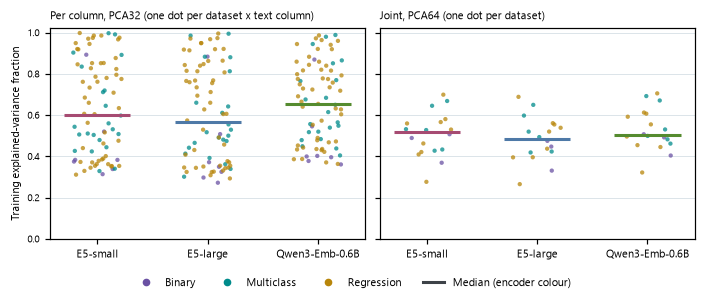

In [5]:
from src.evaluation import pca_variance
report_section("5. Training-only PCA compression")
variance = pca_variance.outer_variance_table()
if variance.empty:
    print("Waiting for the prepared PCA stores: no PCA diagnostics are shown.")
else:
    summary = variance.groupby(["encoder", "pca_scope"], as_index=False).agg(
        fits=("dataset_id", "size"), datasets=("dataset_id", "nunique"),
        median_fraction=("training_explained_variance_fraction", "median"),
        min_fraction=("training_explained_variance_fraction", "min"),
        max_fraction=("training_explained_variance_fraction", "max"))
    display_table("Outer-training PCA fits found per encoder and scope", summary)
    gbfig.render(save, representation_views.pca_variance(variance, name="b2_pca_training_variance"))

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nOnly the verified exports and local caches named above were read; no inference, model training or VSC changes were performed.")

B/B2

1. What is complete: export, provenance and coverage


Notebook execution identity
{
  "code_sha256": "253d5f17bdea4be35b0e853055326f9a06bd5d0a5b2b0c789f83d236fd3c5074",
  "git_head": "0929454751c9921410a46b29506eb6c2b4ca280f",
  "git_dirty": true,
  "tfm_library_pin": "4574eea0c2ce6646b5d2e9c7f53a6ef3882c368c dm-library (remotes/origin/HEAD)\n 248f137046487e0d57360abba1e060420ae54e1a tfm-library (remotes/origin/HEAD)\n 2208cf68d6351eff2cb0ddb5a9eb1d822523457b vsc-library (heads/main-8-g2208cf6)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


Decision-model cohort and members
{
  "decision_cohort": "open_weight",
  "decision_roster": [
    "liquid",
    "liquid_lfm3",
    "perplexity",
    "cloudflare",
    "strands",
    "intern",
    "h2o",
    "sii",
    "kev",
    "decision3",
    "nimble",
    "glide",
    "mammoth",
    "drex_max",
    "knowline",
  